# Capitulo 1

Creciente popularidad de los métodos de ensamble al ser una opción poderosa para tratar el tradeoff entre complejidad y ajuste (fit vs. complexity / bias vs. variance).

Meta estudios como el de Randal S. Olson et al. (2018) muestran el éxito predictivo de estos modelos en conjuntos estructurados de datos sobre modelos individuales. Generalmente estos se combinan con feature engineering.

Formalmente un método de ensamble es un algortimo de machine learning el cual mejora el rendimiento de su predicción agregando predicciones de múltiples estimadores o modelos. En ese sentido se trata de un metaestimador.

El éxito de estos modelos está en la diversidad del ensamble, también conocido como complementariedad de modelos u ortogonalidad de modelos.

Veamos esto con un ejemplo, usemos el conjunto de datos sintéticos llamado Friedman-1, el cuál fue creado para explorar tareas de regresión múltiple.





In [3]:
# Generamos un set de 500 datos, 15 características y un ruido gaussiano con desviación de 0.3

from sklearn.datasets import make_friedman1
X, y = make_friedman1(n_samples=500,
                      n_features=15,
                      noise = 0.3,
                      random_state= 23)

In [4]:
# Dividamos los datos en entrenamiento (67%) y prueba (33%)
# una regla común e útil es el principio de Pareto 80%-20%
# entrenaremos arboles con diferentes profundidades, empezando con d=1 hasta d=10
# repetimos el experimento k=5 veces y promediaremos los resultados (validació cruzada)

import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import ShuffleSplit
from sklearn.model_selection import validation_curve

#establecemos 5 diferentes particiones aleatorias entre entrenamiento y prueba

subsets = ShuffleSplit(n_splits=5,
                      test_size=0.33,
                      random_state=0)

# especificamos el modelo

model = DecisionTreeRegressor()

# para cada partición entrenamos arboles de diferentes profundidades
# posteriormente evaluamos el rendimiento sonbre test usando r2

trn_scores, tst_scores = validation_curve(estimator=model,
                                       X=X,
                                       y=y,
                                       param_name= 'max_depth',
                                       param_range= np.arange(1,11),
                                       cv=subsets,
                                       scoring= "r2")

# promediamos las puntuaciones de evaluación
mean_train_scores = np.mean(trn_scores, axis=1)
mean_test_scores = np.mean(tst_scores, axis=1)

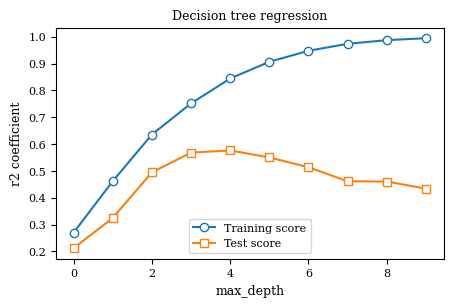

In [24]:
import matplotlib.pyplot as plt

# Configuración global para estilo de artículo científico
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = [
    'Times New Roman',
    'Times',
    'Nimbus Roman',
    'DejaVu Serif',
]
plt.rcParams['font.size'] = 8 # Los artículos científicos usan letra pequeña (8-10pt)
plt.rcParams['axes.titlesize'] = 9
plt.rcParams['axes.labelsize'] = 9

# grafico

fig, ax = plt.subplots(figsize=(5,3))
ax.plot(mean_train_scores, marker = "o", markerfacecolor='white', label = "Training score")
ax.plot(mean_test_scores, marker = "s", markerfacecolor='white', label = "Test score")
ax.set_title('Decision tree regression')
ax.set_xlabel('max_depth')
ax.set_ylabel('r2 coefficient')
ax.legend(loc="lower center")
plt.show()

In [27]:
# Probemos con SVM

from sklearn.svm import SVR

model = SVR(kernel = "rbf", gamma = 0.1)

trn_scores, tst_scores = validation_curve(estimator = model,
                                          X=X,
                                          y=y,
                                          param_name= 'C',
                                          param_range= np.logspace(-2,4,7),
                                          cv=subsets, scoring="r2")

mean_train_scores = np.mean(trn_scores, axis=1)
mean_test_scores = np.mean(tst_scores, axis=1)

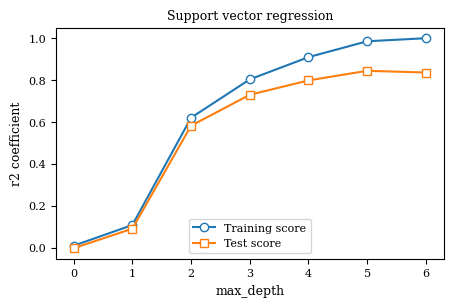

In [29]:
fig, ax = plt.subplots(figsize=(5,3))
ax.plot(mean_train_scores, marker = "o", markerfacecolor='white', label = "Training score")
ax.plot(mean_test_scores, marker = "s", markerfacecolor='white', label = "Test score")
ax.set_title('Support vector regression')
ax.set_xlabel('max_depth')
ax.set_ylabel('r2 coefficient')
ax.legend(loc="lower center")
plt.show()